# 21 · 집합의 순서와 그래프의 이웃을 구분하기

📎 **이번 질문** · 과일 꾸러미의 행 순서는 중요하지 않은데, 과일끼리 연결된 관계가 있다면 어느 이웃을 읽어야 할까요?

같은 과일 특징을 두 가지 문제로 봅니다. Deep Sets는 꾸러미 전체에 숫자 하나를 예측하고, 그래프 attention은 연결된 이웃을 읽어 노드마다 숫자를 예측합니다. 두 모델을 NumPy로 학습하고 모든 파라미터와 입력의 backward를 수치미분으로 확인합니다.

10 GNN의 고정 이웃 평균에서 **학습되는 이웃 비중**으로 넘어가고, Deep Sets에서는 **집합 크기와 중복 정보**를 합·평균이 어떻게 다루는지 새로 확인합니다.

> **용어**
>
> - **집합(set):** 원소의 순서가 없는 모음입니다. 이 노트북의 배열은 중복 원소도 허용하므로 엄밀히는 **중복 허용 집합(multiset)**입니다.
> - **그래프(graph):** 물건을 나타내는 **노드(node)**와 관계를 나타내는 **간선(edge)**의 모음입니다. 인접 행렬 `A[i,j]=1`이면 노드 i가 j의 정보를 읽습니다.
> - **Deep Sets:** 모든 원소에 같은 함수 φ를 적용하고 합·평균으로 모은 뒤 함수 ρ로 출력을 만드는 구조입니다.
> - **GAT(graph attention network):** 허용된 이웃 사이에서 attention 비중을 정해 정보를 합치는 그래프 신경망입니다.

- 준비물: [03 MLP](../00_기초/03_perceptron_to_mlp.ipynb)의 tanh·연쇄법칙, [04 optimizer](../00_기초/04_optimizers.ipynb)의 Adam, [08 attention](../01_아키텍처/08_attention.ipynb)의 softmax·가중합, [10 GNN](../01_아키텍처/10_gnn.ipynb)의 이웃 집계, [15 평가](../02_연결/15_experiments_evaluation.ipynb)의 독립 분할.
- 도착점: 순열 불변·등변, sum·mean의 정보 차이, padding과 고립 노드, 값·점수 두 경로의 backward를 구현합니다.
- 연결: [19 ViT](19_vit.ipynb)와 [20 seq2seq](20_sequence_encoder_decoder.ipynb)에서는 위치·순서가 의미를 가집니다. 여기서는 위치나 노드 ID를 입력에 넣지 않습니다. 다른 노트북의 실행 상태는 필요하지 않습니다.

### 읽는 법

| 표시 | 뜻 | 읽는 방법 |
|---|---|---|
| 🔑 핵심 | 설명·수식·구현 | 축을 적고 같은 계산을 다시 씁니다 |
| 🔍 확인 | 그림·검산 해석 | 실제 값과 주장하는 성질을 대조합니다 |
| 📎 참고 | 용어·코드·연결 | 낯선 표현을 바로 풀이합니다 |
| ✏️ 연습 | 핵심 한두 줄 | 정답을 접고 `run_check`를 실행합니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. 행을 바꾸어도 전체 출력은 같고, 노드 출력은 같은 순서로 움직여야 합니다. 그래프는 특징과 인접 행렬의 두 축을 함께 바꿉니다.
2. 평균과 정규화 attention은 원소·이웃의 개수 정보를 잃을 수 있습니다. mask는 값이 0인지가 아니라 실제 원소인지 표시합니다.
3. GAT의 투영된 특징은 **값 경로와 점수 경로** 양쪽에 쓰입니다. 두 기울기를 합하고, masked edge와 padding 입력의 기울기는 0인지 검산합니다.

| 기호 | shape | 축의 뜻 |
|---|---|---|
| $X$ | $(B,N,D)$ | 꾸러미/graph 수, 최대 원소 수($N\ge1$), 특징 수(여기서는 2) |
| $V$ | $(B,N)$ | 실제 원소이면 1, padding이면 0 |
| $A,M,\alpha$ | $(B,N,N)$ | 읽는 노드 i, 읽히는 이웃 j의 관계·허용 mask·비중 |
| $H,Z$ | $(B,N,F)$ | 각 원소의 공유 특징 |
| 집합 출력 / 노드 출력 | $(B,1)$ / $(B,N,1)$ | 꾸러미 전체 / 노드별 회귀 예측 |

[전체 경로](../../docs/CURRICULUM.md) · [그림 설계](../../docs/DESIGN.md) · [그림 보조 코드](../../src/utils/sets_graph_plots.py)

In [1]:
# 준비 셀: 실행만 하고 넘어가도 됩니다.
import sys
from pathlib import Path
import time
import numpy as np
project_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0,str(project_root))
from src.utils import setup_plots,run_check
from src.utils.gradcheck import numerical_gradient,rel_error
from src.utils.sets_graph_plots import (
    plot_permutation,plot_pool_cardinality,plot_neighbor_mask,plot_gat_aggregation,
    plot_task_plan,plot_learning_curves,plot_heldout_predictions,plot_size_degree_metrics,
)
setup_plots()
print('NumPy',np.__version__,'· CPU float64 · 외부 데이터 다운로드 없음')

NumPy 2.4.6 · CPU float64 · 외부 데이터 다운로드 없음


## 🔑 1. 행 순서는 바뀌어도 물건은 같습니다

**이 절에서 가져갈 것:** 공유 원소 함수의 출력은 행과 함께 움직이고, 원소 축의 합·평균은 순서에 무관합니다.

꾸러미에 과일 세 개가 있습니다. 목록의 첫째와 셋째를 바꾸어 적어도 꾸러미는 같습니다. 그러나 과일마다 붙인 점수는 어느 과일의 점수인지 유지하며 함께 움직여야 합니다. 순열 행렬 $P$로 행을 바꾸면

$$\phi(PX)=P\phi(X)\quad\text{(등변)},\qquad f(PX)=f(X)\quad\text{(불변)}.$$

각 행에 같은 $\phi(x)=x^\top w$를 쓰면 등변이고, 행들의 합을 내면 불변입니다. 손계산 $X=[(1,0),(0,2),(2,1)]$, $w=(2,-1)$의 행 점수는 $(2,-2,3)$, 합은 3입니다. 새 순서 $(2,0,1)$에서는 점수도 $(3,2,-2)$가 됩니다.

> **용어**
>
> - **순열(permutation):** 원소를 추가·삭제하지 않고 순서만 바꾸는 일입니다. `X[order]`가 행을 재배열합니다.
> - **순열 불변(invariant):** 입력 순서를 바꾸어도 출력이 같은 성질입니다.
> - **순열 등변(equivariant):** 입력 순서를 바꾸면 출력도 같은 순서로 바뀌는 성질입니다.
> - **padding:** 길이가 다른 꾸러미를 같은 배열에 담기 위해 채운 가짜 자리입니다. 별도 `valid`로 제외합니다.

> **코드** · `X[None]`은 맨 앞에 길이 1인 배치 축을 넣습니다. `valid[..., None]`은 마지막에 길이 1인 축을 넣어 모든 특징에 같은 mask를 적용합니다. `np.stack([a,b], axis=1)`은 두 배열을 새 열 축에 쌓습니다.

In [2]:
fruit_X = np.array([[1.,0.],[0.,2.],[2.,1.]])
fruit_w = np.array([2.,-1.])
fruit_order = np.array([2,0,1])
fruit_scores = fruit_X @ fruit_w
fruit_reordered = fruit_X[fruit_order]
fruit_changed_scores = fruit_reordered @ fruit_w
fruit_score_columns = np.stack([fruit_scores,fruit_changed_scores],axis=1)
fruit_totals = np.array([[fruit_scores.sum()],[fruit_changed_scores.sum()]])

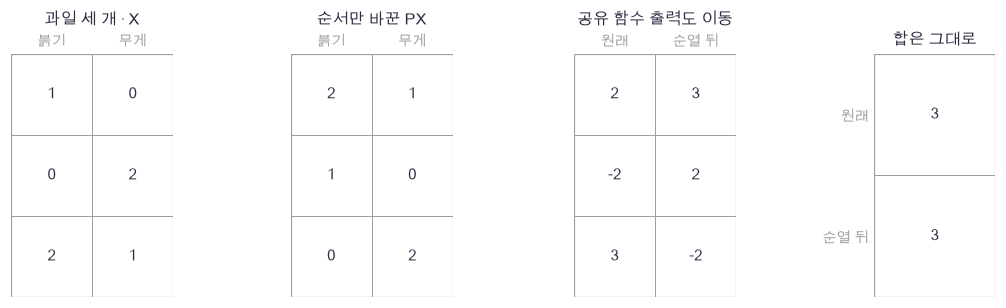

In [3]:
plot_permutation(fruit_X,fruit_reordered,fruit_score_columns,fruit_totals)

🔍 **확인** · 가운데의 두 점수 열은 같은 과일끼리 같은 행에 놓인 비교가 아니라 **원래 순서와 새 순서의 목록**입니다. 행별 점수는 이동하지만 마지막 합 3은 그대로입니다. 첫 행에만 특별한 가중치를 붙이면 이 성질을 잃습니다.

In [4]:
def shared_linear_loop(X,w):
    """모든 행에 같은 내적을 적용합니다. X:(N,D), w:(D,) → score:(N,)."""
    score = np.zeros(len(X))
    for i in range(len(X)):
        for d in range(len(w)):
            score[i] += X[i,d]*w[d]
    return score

In [5]:
def pool_loop(X, valid, mode='sum'):
    """유효 원소의 합/평균을 좌표 반복으로 계산합니다. X:(B,N,D), valid:(B,N) → (B,D)."""
    B, N, D = X.shape
    result = np.zeros((B, D))
    for b in range(B):
        count = 0
        for i in range(N):
            if valid[b, i]:
                result[b] += X[b, i]
                count += 1
        if mode == 'mean':
            result[b] /= max(count, 1)
    return result

In [6]:
# 쓰는 것: fruit_X (1절) · fruit_changed_scores (1절) · fruit_order (1절) · fruit_scores (1절) · fruit_w (1절)
np.testing.assert_allclose(fruit_scores,[2.,-2.,3.])  # 검산: 세 내적의 손계산
np.testing.assert_allclose(shared_linear_loop(fruit_X,fruit_w),fruit_scores)  # 검산: 반복문과 행렬곱
np.testing.assert_allclose(fruit_changed_scores,fruit_scores[fruit_order])  # 검산: 공유 함수의 등변성
pool_X = np.array([[[1.,0.],[0.,2.],[2.,1.],[100.,-100.]]])
pool_valid = np.array([[True,True,True,False]])
pool_sum = np.sum(pool_X*pool_valid[...,None],axis=1)
pool_mean = pool_sum/pool_valid.sum(axis=1,keepdims=True)
np.testing.assert_allclose(pool_sum,[[3.,3.]])  # 검산: padding을 제외한 손계산 합
np.testing.assert_allclose(pool_loop(pool_X,pool_valid),pool_sum)  # 검산: 합의 반복문·벡터화
np.testing.assert_allclose(pool_loop(pool_X,pool_valid,'mean'),pool_mean)  # 검산: 평균의 반복문·벡터화
print('공유 함수·masked 합·평균의 손계산과 순열 성질 통과')

공유 함수·masked 합·평균의 손계산과 순열 성질 통과


### ✏️ 연습 1 · 가짜 행을 제외한 합

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

`X:(B,N,D)`에서 실제 원소의 특징만 원소 축으로 더하세요. 결과는 `(B,D)`입니다.

In [7]:
def exercise_masked_sum(X,valid):
    """연습 1: 실제 원소만 합합니다. X:(B,N,D), valid:(B,N) → (B,D)."""
    ### 구현할 내용: valid를 특징 축에 broadcast한 뒤 원소 축 합
    raise NotImplementedError
    return total

In [8]:
def check_masked_sum(candidate):
    """작은 두 꾸러미의 합을 손계산합니다."""
    X = np.array([[[1.,2.],[9.,9.]],[[3.,4.],[5.,6.]]])
    V = np.array([[1,0],[1,1]],bool)
    np.testing.assert_allclose(candidate(X,V),[[1.,2.],[8.,10.]])  # 검산: 가짜 행 제외
    print('masked 합: 손계산과 일치합니다.')

run_check(check_masked_sum,exercise_masked_sum,hint='total = np.sum(X*valid[...,None],axis=1)')

☐ exercise_masked_sum: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: total = np.sum(X*valid[...,None],axis=1)


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
total = np.sum(X*valid[...,None],axis=1)
```

</details>

## 🔑 2. 같은 함수로 읽고, 합친 뒤 꾸러미를 예측합니다

**이 절에서 가져갈 것:** Deep Sets를 끝까지 미분하고, 합과 평균이 중복·개수에 담는 정보가 다름을 확인합니다.

꾸러미 전체를 한 번 더 복제하면 총량은 두 배가 되지만 과일의 평균 성질은 같습니다. 원소별 특징 $H_{bi}=\tanh(x_{bi}W_\phi+b_\phi)$를 만들고

$$s_{bi}=\begin{cases}V_{bi}&\text{sum}\\ V_{bi}/\max(n_b,1)&\text{mean}\end{cases},\quad
n_b=\sum_i V_{bi},\quad g_b=\sum_i s_{bi}H_{bi},$$
$$R_b=\tanh(g_bW_\rho+b_\rho),\qquad \hat y_b=R_bW_o+b_o$$

로 꾸러미 출력 하나를 만듭니다. $W_\phi:(D,F)$, $W_\rho:(F,R)$, $W_o:(R,1)$입니다. 공유 함수와 합 때문에 두 모드 모두 순열 불변입니다. **이 유한 폭 모델이 모든 집합 함수를 표현한다는 주장은 하지 않습니다.** 이 절은 구조가 보장하는 순열 성질을 확인합니다. [Zaheer 외, Deep Sets](https://arxiv.org/abs/1703.06114).

역방향에서 $dR_{pre}=(G W_o^\top)\odot(1-R^2)$, $dg=dR_{pre}W_\rho^\top$이고

$$dH_{bi}=s_{bi}\,dg_b,\qquad dZ_{bi}=dH_{bi}\odot(1-H_{bi}^2),\qquad
dW_\phi=\sum_{b,i}x_{bi}^\top dZ_{bi}.$$

합은 각 원소에 같은 상류 기울기를 보내고, 평균은 원소 수로 나누어 보냅니다. padding의 계수는 0입니다. 빈 꾸러미는 $g=0$으로 정의하지만, **최종 출력은 ρ의 편향 때문에 꼭 0일 필요가 없습니다**. 아래 학습 데이터는 빈 꾸러미를 만들지 않습니다.

> **용어** · **readout**은 원소·노드별 특징을 모아 전체 출력으로 바꾸는 부분입니다. **cardinality**는 중복을 포함해 실제 원소가 몇 개인지 세는 수 $n_b$입니다. **tanh**는 실수를 −1과 1 사이로 바꾸며 도함수는 $1-\tanh^2(z)$입니다.

> **코드** · `np.maximum(count,1)`은 빈 꾸러미의 0 나눗셈을 막습니다. `reshape(-1,D)`는 배치·원소 축을 하나로 합쳐 같은 affine 미분을 한 번에 계산합니다. `rng.normal(..., size)`는 지정한 shape의 정규 난수 배열을 만듭니다.

In [9]:
# 쓰는 것: fruit_X (1절)
pool_demo_H = np.tanh(fruit_X @ np.array([[.4,-.2],[.1,.3]]))
pool_demo_twice = np.concatenate([pool_demo_H,pool_demo_H],axis=0)
pool_demo_sums = np.stack([pool_demo_H.sum(axis=0),pool_demo_twice.sum(axis=0)])
pool_demo_means = np.stack([pool_demo_H.mean(axis=0),pool_demo_twice.mean(axis=0)])

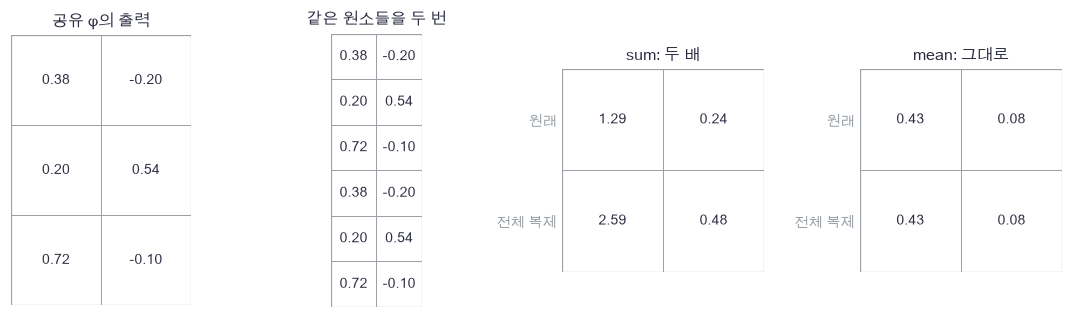

In [10]:
plot_pool_cardinality(pool_demo_H,pool_demo_twice,pool_demo_sums,pool_demo_means)

🔍 **확인** · 전체 원소를 두 번씩 넣으면 pooling된 특징 g의 mean은 정확히 같고 sum은 두 배입니다. 비선형 ρ를 지난 **최종 예측까지 두 배라는 뜻은 아닙니다**. sum이 항상 개수를 복원한다는 뜻도 아닙니다. 예를 들어 φ에 상수 1 채널을 넣으면 그 채널의 합은 개수이고 평균은 항상 1이므로, 개수 정보를 보존하는 한 방법이 됩니다.

아래 검산은 모든 원소의 중심차분을 하며 sum·mean 두 모드를 모두 검사합니다. 빈 꾸러미와 큰 가짜 값을 넣은 padding도 별도로 확인합니다.

In [11]:
def init_sets(seed=210, hidden=8, readout=6):
    """공유 φ와 ρ의 가중치를 만듭니다. 입력2 → hidden → pool → readout → 출력1."""
    rng = np.random.default_rng(seed)
    return {'Wp':rng.normal(0,.5,(2,hidden)), 'bp':rng.normal(0,.2,hidden),
            'Wr':rng.normal(0,1/np.sqrt(hidden),(hidden,readout)), 'br':np.zeros(readout),
            'Wo':rng.normal(0,1/np.sqrt(readout),(readout,1)), 'bo':np.zeros(1)}

In [12]:
def sets_forward(X, valid, parameters, mode='mean'):
    """Deep Sets: 공유 tanh φ→masked sum/mean→tanh ρ. X:(B,N,2) → prediction:(B,1), cache."""
    H = np.tanh(X @ parameters['Wp'] + parameters['bp'])
    denominator = np.maximum(valid.sum(axis=1, keepdims=True), 1) if mode == 'mean' else np.ones((len(X),1))
    weights = valid/denominator
    pooled = np.sum(H*weights[..., None], axis=1)
    R = np.tanh(pooled @ parameters['Wr'] + parameters['br'])
    output = R @ parameters['Wo'] + parameters['bo']
    return output, (X, H, weights, pooled, R, parameters)

In [13]:
def sets_backward(G, cache):
    """Deep Sets 전체 backward. G:(B,1) → dX:(B,N,2), 여섯 파라미터 배열의 gradient."""
    X, H, weights, pooled, R, parameters = cache
    gradients = {'Wo':R.T@G, 'bo':G.sum(axis=0)}
    dR = (G @ parameters['Wo'].T)*(1-R**2)
    gradients['Wr'], gradients['br'] = pooled.T@dR, dR.sum(axis=0)
    dpool = dR @ parameters['Wr'].T
    dH = dpool[:, None, :]*weights[..., None]
    dpre = dH*(1-H**2)
    gradients['Wp'] = X.reshape(-1,X.shape[-1]).T @ dpre.reshape(-1,H.shape[-1])
    gradients['bp'] = dpre.sum(axis=(0,1))
    return dpre @ parameters['Wp'].T, gradients

In [14]:
def check_sets_gradients(mode):
    """작은 Deep Sets의 모든 파라미터·입력을 중심차분합니다. padding 포함, 상대오차 사전 반환."""
    # 1. 다른 크기의 꾸러미와 6개 파라미터 배열을 준비합니다.
    X = np.array([[[.2,-.3],[.7,.4],[8.,-9.]],[[.1,.9],[-.5,.2],[.3,-.6]]])
    valid = np.array([[1,1,0],[1,1,1]],bool)
    parameters = init_sets(220,3,2)
    output,cache = sets_forward(X,valid,parameters,mode)
    G = np.array([[.6],[-.4]])
    dX,gradients = sets_backward(G,cache)
    def scalar():
        """검산 목적: 두 꾸러미 출력과 고정 상류 기울기의 내적."""
        return float(np.sum(sets_forward(X,valid,parameters,mode)[0]*G))
    # 2. 모든 원소를 흔들고 각각의 해석 미분과 대조합니다.
    errors = {}
    for key,value in parameters.items():
        numeric = numerical_gradient(scalar,value)
        np.testing.assert_allclose(gradients[key],numeric,atol=1e-8,rtol=2e-6)  # 검산: 모든 parameter 원소
        errors[key] = rel_error(gradients[key],numeric)
    numeric_X = numerical_gradient(scalar,X)
    np.testing.assert_allclose(dX,numeric_X,atol=1e-8,rtol=2e-6)  # 검산: 실제·padding 입력 전체
    np.testing.assert_array_equal(dX[~valid],0.)  # 검산: padding에는 기울기 없음
    errors['X'] = rel_error(dX,numeric_X)
    assert max(errors.values()) < 2e-6, '모든 배열의 상대오차가 허용 범위여야 합니다'
    return errors

In [15]:
# 쓰는 것: fruit_X (1절) · fruit_order (1절) · init_sets (2절)
print('Deep Sets sum 미분:',check_sets_gradients('sum'))
print('Deep Sets mean 미분:',check_sets_gradients('mean'))
sets_probe_parameters = init_sets(221,3,2)
sets_probe_X = fruit_X[None]/2
sets_probe_valid = np.ones((1,3),bool)
sets_probe_output = sets_forward(sets_probe_X,sets_probe_valid,sets_probe_parameters)[0]
sets_permuted = sets_forward(sets_probe_X[:,fruit_order],sets_probe_valid[:,fruit_order],sets_probe_parameters)[0]
np.testing.assert_allclose(sets_permuted,sets_probe_output)  # 검산: 전체 예측의 순열 불변성
sets_duplicated = sets_forward(np.repeat(sets_probe_X,2,axis=1),np.ones((1,6),bool),sets_probe_parameters)[0]
np.testing.assert_allclose(sets_duplicated,sets_probe_output)  # 검산: 전체 복제에도 mean 출력은 동일
empty_output,empty_cache = sets_forward(np.zeros((1,3,2)),np.zeros((1,3),bool),sets_probe_parameters)
np.testing.assert_array_equal(empty_cache[3],0.)  # 검산: 빈 꾸러미의 pool은 0
empty_expected = np.tanh(sets_probe_parameters['br']) @ sets_probe_parameters['Wo'] + sets_probe_parameters['bo']
np.testing.assert_allclose(empty_output[0],empty_expected)  # 검산: 출력은 readout의 0 입력 응답
print('순열·전체 복제·빈 꾸러미 규약 통과')

Deep Sets sum 미분: {'Wp': 3.72256674660433e-10, 'bp': 1.068943195880724e-10, 'Wr': 4.209612722363959e-10, 'br': 1.5186105931770012e-10, 'Wo': 4.25753235962714e-10, 'bo': 3.063116426232786e-10, 'X': 4.243148083151665e-10}
Deep Sets mean 미분: {'Wp': 2.1911792085820092e-10, 'bp': 1.4519212166361864e-10, 'Wr': 2.0860070063957595e-10, 'br': 8.437407187252654e-11, 'Wo': 1.8254832422224388e-10, 'bo': 4.063305247825611e-11, 'X': 3.013157936686032e-10}
순열·전체 복제·빈 꾸러미 규약 통과


### ✏️ 연습 2 · 평균 pooling의 backward

`G:(B,F)`가 평균 특징으로 들어온 기울기입니다. 각 실제 원소에 `G/n`을 보내고 padding에는 0을 보내세요.

In [16]:
def exercise_mean_pool_backward(G,valid):
    """연습 2: 평균 pool backward. G:(B,F), valid:(B,N) → (B,N,F)."""
    count = np.maximum(valid.sum(axis=1,keepdims=True),1)
    ### 구현할 내용: 원소 축을 새로 넣은 G에 valid/count 곱하기
    raise NotImplementedError
    return dH

In [17]:
def check_mean_pool_backward(candidate):
    """두 실제 원소·빈 꾸러미의 기울기를 손계산합니다."""
    G = np.array([[6.,2.],[5.,7.]])
    V = np.array([[1,0,1],[0,0,0]],bool)
    expected = np.array([[[3.,1.],[0.,0.],[3.,1.]],[[0.,0.],[0.,0.],[0.,0.]]])
    np.testing.assert_allclose(candidate(G,V),expected)  # 검산: 실제 원소 둘에 절반씩
    print('mean backward: 손계산과 일치합니다.')

run_check(check_mean_pool_backward,exercise_mean_pool_backward,hint='dH = G[:,None,:]*(valid/count)[...,None]')

☐ exercise_mean_pool_backward: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: dH = G[:,None,:]*(valid/count)[...,None]


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dH = G[:,None,:]*(valid/count)[...,None]
```

</details>

## 🔑 3. 실제 이웃 안에서만 softmax를 계산합니다

**이 절에서 가져갈 것:** self-loop·고립 노드·padding의 규약을 구분하고 masked softmax와 미분을 안정적으로 구현합니다.

과일들 사이에 서로 참고할 관계가 있습니다. 노드 0이 1을 읽는 관계는 `A[0,1]=1`입니다. **10 GNN과 같이 행 i가 받는 쪽, 열 j가 보내는 쪽**입니다. 그림의 노드 2는 다른 이웃이 없지만 실제 노드이고, 마지막 행은 가짜 padding입니다.

이 노트북은 실제 노드에 self-loop를 넣습니다. $M_{ij}=(A_{ij}\lor 1[i=j])V_iV_j$이고

$$\alpha_{ij}=\begin{cases}\exp(e_{ij}-m_i)/\sum_{k:M_{ik}=1}\exp(e_{ik}-m_i)&M_{ij}=1\\0&M_{ij}=0\end{cases},\quad
m_i=\max_{j:M_{ij}=1}e_{ij}.$$

고립된 실제 노드는 자기 자신만 읽으므로 비중이 1입니다. padding은 query와 key 양쪽에서 막습니다. 일반 함수는 **허용 이웃이 전혀 없는 행의 비중을 모두 0**으로 반환하고, 그 행의 backward도 0으로 둡니다. 따라서 padding 행의 합은 0이고 실제 노드 행의 합은 1입니다.

self-loop를 끈 변형에서는 고립 노드의 집계가 0이지만, 뒤에 편향이 있으면 최종 예측은 0이 아닐 수 있습니다. 반면 padding의 최종 출력은 별도의 valid 곱으로 0으로 만듭니다.

상류 기울기가 $G^\alpha$이면 마지막 이웃 축에서

$$\frac{\partial L}{\partial e_{ij}}=\alpha_{ij}\left(G^\alpha_{ij}-\sum_k\alpha_{ik}G^\alpha_{ik}\right).$$

masked edge는 $\alpha=0$이므로 점수 미분도 0입니다. 고정 boolean 인접 행렬 자체는 미분 대상이 아닙니다.

> **용어** · **self-loop**는 자신을 이웃에 넣은 관계입니다. **고립 노드(isolated node)**는 다른 이웃이 없는 실제 노드입니다. **이웃 softmax**는 허용된 이웃들의 지수값만 더해 정규화하는 연산입니다.

> **코드** · `|`와 `&`는 boolean 배열의 자리별 OR와 AND입니다. `np.eye(N,dtype=bool)`은 자기 자신을 표시하는 대각선입니다. `np.where(mask,a,b)`는 참인 자리에서 a를, 나머지에서 b를 고릅니다. `np.divide(a,b,out=zeros,where=b>0)`는 양수 분모만 나누고 나머지를 0으로 남겨 0/0을 피합니다.

In [18]:
neighbor_features = np.array([[1.],[3.],[5.],[100.]])
neighbor_valid = np.array([[1,1,1,0]],bool)
neighbor_A = np.array([[[0,1,0,1],[1,0,0,0],[0,0,0,0],[1,1,1,1]]],bool)
neighbor_mask = (neighbor_A | np.eye(4,dtype=bool)[None]) & neighbor_valid[:,:,None] & neighbor_valid[:,None,:]
neighbor_scores = np.array([[[0.,np.log(3),2.,99.],[0.,0.,3.,99.],[4.,3.,0.,99.],[7.,7.,7.,7.]]])
neighbor_expected = np.array([[[.25,.75,0.,0.],[.5,.5,0.,0.],[0.,0.,1.,0.],[0.,0.,0.,0.]]])
neighbor_aggregate = neighbor_expected @ neighbor_features

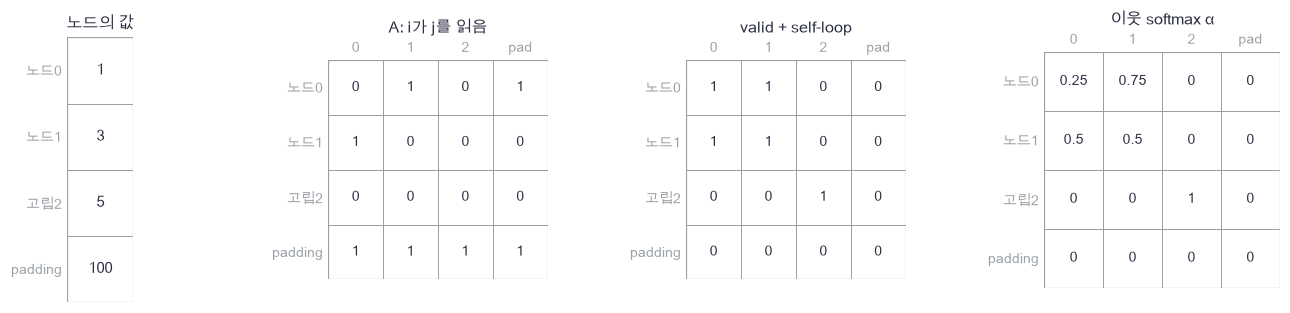

In [19]:
plot_neighbor_mask(neighbor_features,neighbor_A[0],neighbor_mask[0],neighbor_expected[0])

🔍 **확인** · 첫 행은 $1/(1+3)$과 $3/(1+3)$이므로 .25·.75입니다. 고립 노드 2는 자기 값만 읽고, padding은 모든 비중이 0입니다. 가짜 특징 100이 실제 출력으로 새어 들어오면 mask의 두 축 중 하나를 놓쳤는지 확인합니다.

In [20]:
def edge_mask(adjacency, valid, self_loops=True):
    """A[i,j]는 i가 j를 읽는다는 뜻입니다. 실제 노드 쌍만 허용하고 선택적으로 self-loop를 넣습니다."""
    mask = adjacency.astype(bool) & valid[:, :, None] & valid[:, None, :]
    if self_loops:
        diagonal = np.eye(valid.shape[1], dtype=bool)[None]
        mask = mask | (diagonal & valid[:, :, None] & valid[:, None, :])
    return mask

In [21]:
def masked_softmax(scores, mask):
    """마지막 이웃 축 softmax. scores/mask:(B,N,N) → 같은 shape, 허용 이웃이 없는 행은 0."""
    masked = np.where(mask, scores, -np.inf)
    maximum = masked.max(axis=-1, keepdims=True)
    maximum = np.where(np.isfinite(maximum), maximum, 0.)
    exponential = np.exp(np.where(mask, scores-maximum, -np.inf))
    denominator = exponential.sum(axis=-1, keepdims=True)
    return np.divide(exponential, denominator, out=np.zeros_like(exponential), where=denominator>0)

In [22]:
def masked_softmax_backward(G, weights):
    """이웃 softmax의 Jacobian-vector 곱. G,weights:(B,N,N) → dscore, masked 위치는 정확히 0."""
    return weights*(G-np.sum(G*weights, axis=-1, keepdims=True))

In [23]:
# 쓰는 것: neighbor_A (3절) · neighbor_expected (3절) · neighbor_features (3절) · neighbor_mask (3절) · neighbor_scores (3절) · neighbor_valid (3절)
np.testing.assert_array_equal(edge_mask(neighbor_A,neighbor_valid),neighbor_mask)  # 검산: self-loop와 valid 양축
neighbor_actual = masked_softmax(neighbor_scores,neighbor_mask)
np.testing.assert_allclose(neighbor_actual,neighbor_expected)  # 검산: .25/.75·고립·padding 손계산
np.testing.assert_allclose(neighbor_actual @ neighbor_features,[[[2.5],[2.],[5.],[0.]]])  # 검산: 가중합 손계산
np.testing.assert_allclose(neighbor_actual.sum(axis=-1),neighbor_valid.astype(float))  # 검산: 실제 행1·padding행0
empty_attention = masked_softmax(np.full((1,2,2),1000.),np.zeros((1,2,2),bool))
np.testing.assert_array_equal(empty_attention,0.)  # 검산: all-masked 행은0
np.testing.assert_array_equal(masked_softmax_backward(np.ones_like(empty_attention),empty_attention),0.)  # 검산: 빈 행의 미분도0
extreme_attention = masked_softmax(np.full((1,2,2),1000.),np.ones((1,2,2),bool))
np.testing.assert_allclose(extreme_attention,.5)  # 검산: 큰 같은 점수도 유한한 균등 비중
neighbor_G = np.array([[[2.,-2.,5.,7.],[1.,3.,4.,5.],[3.,2.,1.,9.],[1.,2.,3.,4.]]])
neighbor_dscore = masked_softmax_backward(neighbor_G,neighbor_actual)
np.testing.assert_allclose(neighbor_dscore[0,0],[.75,-.75,0.,0.])  # 검산: 첫 행 softmax 미분 손계산
np.testing.assert_array_equal(neighbor_dscore[~neighbor_mask],0.)  # 검산: 모든 masked edge 미분0
print('이웃 정규화·고립·padding·극단 점수·masked 미분 통과')

이웃 정규화·고립·padding·극단 점수·masked 미분 통과


In [24]:
# 쓰는 것: neighbor_features (3절) · neighbor_mask (3절) · neighbor_scores (3절)
wrong_attention = masked_softmax(neighbor_scores,np.ones_like(neighbor_mask))
wrong_output = wrong_attention @ neighbor_features
assert wrong_output[0,0,0] > 90., 'mask를 빼면 큰 padding 값이 첫 출력에 섞여야 합니다'
np.testing.assert_allclose(np.array([1.]) @ np.array([2.]),2.)  # 검산: 이웃 하나의 값2
np.testing.assert_allclose(np.full(3,1/3) @ np.full(3,2.),2.)  # 검산: 같은 이웃 셋이어도 평균은2
print('mask 누락의 잘못된 첫 출력:',wrong_output[0,0,0])

mask 누락의 잘못된 첫 출력: 100.0


🔍 **확인** · 정규화한 가중합은 이웃이 하나인지 셋인지 항상 구별하지는 못합니다. 모든 이웃 특징이 같으면 어느 양의 비중으로 평균해도 같은 값입니다. 개수·차수를 써야 하는 과제라면 별도 특징이나 합 집계가 필요한지 검토해야 합니다. 이 모델에는 위치나 노드 ID도 없으므로 대칭적인 노드들을 임의로 구별할 수 없습니다.

### ✏️ 연습 3 · 이웃 softmax의 backward

마지막 축이 이웃입니다. `G`와 `alpha`가 같은 `(B,N,N)`일 때 softmax의 Jacobian을 큰 행렬로 만들지 말고 한 줄로 계산하세요.

In [25]:
def exercise_neighbor_softmax_backward(G,alpha):
    """연습 3: 이웃 softmax 미분. 입력 두 배열:(B,N,N) → 같은 shape."""
    ### 구현할 내용: alpha * (G - 이웃 축의 alpha*G 합)
    raise NotImplementedError
    return dscore

In [26]:
def check_neighbor_softmax_backward(candidate):
    """비중(.25,.75,0)과 빈 행을 손계산합니다."""
    alpha = np.array([[[.25,.75,0.],[0.,0.,0.]]])
    G = np.array([[[2.,-2.,99.],[3.,4.,5.]]])
    np.testing.assert_allclose(candidate(G,alpha),[[[.75,-.75,0.],[0.,0.,0.]]])  # 검산: masked·빈 행은0
    print('이웃 softmax backward: 손계산과 일치합니다.')

run_check(check_neighbor_softmax_backward,exercise_neighbor_softmax_backward,hint='dscore = alpha*(G-np.sum(alpha*G,axis=-1,keepdims=True))')

☐ exercise_neighbor_softmax_backward: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: dscore = alpha*(G-np.sum(alpha*G,axis=-1,keepdims=True))


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dscore = alpha*(G-np.sum(alpha*G,axis=-1,keepdims=True))
```

</details>

## 🔑 4. GAT의 값 경로와 점수 경로를 함께 미분합니다

**이 절에서 가져갈 것:** additive 이웃 점수와 실제 집계를 구현하고, 공유 투영으로 돌아오는 두 기울기를 합합니다.

10 GNN에서는 정해진 이웃 평균을 사용했습니다. 여기서는 현재 특징을 보고 이웃별 비중을 학습합니다. 같은 투영 $Z=XW$를 만들고 원 GAT의 additive 점수를 작은 한 head로 구성합니다.

$$r_{ij}=a_L^\top Z_i+a_R^\top Z_j,\quad e_{ij}=\ell(r_{ij}),\quad
\ell(r)=\begin{cases}r&r\ge0\\0.2r&r<0\end{cases},$$
$$\alpha=\operatorname{masked\ softmax}(e,M),\quad T=\alpha Z,\quad H=\tanh T,\quad \hat y=(H W_o+b_o)V.$$

$W:(D,F)$, $a_L,a_R:(F,)$, $W_o:(F,1)$입니다. 두 벡터로 쓴 점수는 연결 벡터 $[Z_i,Z_j]$에 한 벡터를 내적한 것과 같습니다. [Veličković 외, Graph Attention Networks](https://arxiv.org/abs/1710.10903)의 이웃 제한·additive LeakyReLU 점수 원리를 사용하되 **1 head·tanh·회귀 head로 줄인 교육용 모델**입니다. 원 논문의 다중 head·전체 실험을 재현하는 구현은 아닙니다.

$G^T=(G^yW_o^\top)\odot(1-H^2)$일 때

$$G^\alpha=G^T Z^\top,\quad G^Z_{value}=\alpha^\top G^T,\quad
G^r=\operatorname{softmax\_backward}(G^\alpha,\alpha)\odot\ell'(r).$$

각 노드의 **받는 쪽** 점수 기여는 $u_i=\sum_j G^r_{ij}$이고 **보내는 쪽** 기여는 $v_j=\sum_i G^r_{ij}$입니다.

$$da_L=\sum_{b,i}Z_{bi}u_{bi},\quad da_R=\sum_{b,j}Z_{bj}v_{bj},\quad
G^Z_{score}=u[...,None]a_L+v[...,None]a_R,$$
$$dW=\sum_{b,i}X_{bi}^\top(G^Z_{value}+G^Z_{score})_{bi},\quad dX=(G^Z_{value}+G^Z_{score})W^\top.$$

투영된 특징은 가중합의 **값**이면서 attention **점수의 입력**입니다. 한 경로를 빼면 전체 미분이 틀립니다.

> **용어** · **additive attention**은 두 노드의 선형 점수를 더해 비중을 정하는 방식입니다. **LeakyReLU**는 음수에서도 작은 기울기 .2를 남기는 조각별 선형 활성화입니다. 0에서 꺾이므로 그 근처를 피해 수치미분합니다. **head**는 점수·가중합 계산 한 묶음입니다.

> **코드** · `(B,N,F) @ (B,F,N)`은 배치마다 행렬곱합니다. `swapaxes(-1,-2)`는 마지막 두 축만 맞바꾸어 배치를 유지합니다. `(Z@aL)[:,:,None]`과 `(Z@aR)[:,None,:]`를 더하면 받는 i와 보내는 j의 모든 쌍 점수가 됩니다.

In [27]:
# 쓰는 것: edge_mask (3절) · fruit_X (1절) · masked_softmax (3절)
gat_demo_X = fruit_X/2
gat_demo_W = np.array([[.6,-.4],[.2,.5]])
gat_demo_Z = gat_demo_X @ gat_demo_W
gat_demo_raw = (gat_demo_Z @ np.array([.4,-.3]))[:,None] + (gat_demo_Z @ np.array([-.2,.5]))[None,:]
gat_demo_scores = np.where(gat_demo_raw>=0,gat_demo_raw,.2*gat_demo_raw)
gat_demo_A = np.array([[[0,1,0],[1,0,1],[0,0,0]]],bool)
gat_demo_valid = np.ones((1,3),bool)
gat_demo_alpha = masked_softmax(gat_demo_scores[None],edge_mask(gat_demo_A,gat_demo_valid))[0]
gat_demo_H = np.tanh(gat_demo_alpha @ gat_demo_Z)

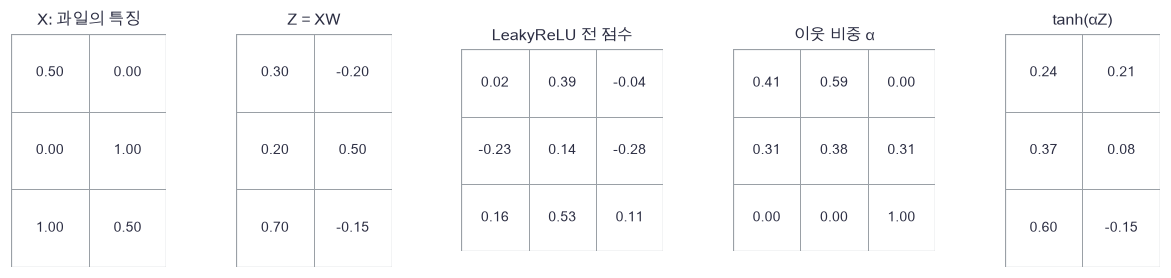

In [28]:
plot_gat_aggregation(gat_demo_X,gat_demo_Z,gat_demo_raw,gat_demo_alpha,gat_demo_H)

🔍 **확인** · 행마다 허용 이웃이 다르므로 softmax의 분모도 다릅니다. 마지막 노드는 자기 자신만 읽어 투영 특징의 tanh가 됩니다. attention 표만으로 중요한 원인의 설명을 얻었다고 단정하지 않고, 이 표를 계산에 쓰이는 비중으로 읽습니다.

In [29]:
def init_gat(seed=211, hidden=8):
    """한 head additive GAT의 파라미터. 입력2→hidden→노드 출력1, W/aL/aR/Wo/bo 다섯 배열."""
    rng = np.random.default_rng(seed)
    return {'W':rng.normal(0,.5,(2,hidden)), 'aL':rng.normal(0,.3,hidden),
            'aR':rng.normal(0,.3,hidden), 'Wo':rng.normal(0,1/np.sqrt(hidden),(hidden,1)), 'bo':np.zeros(1)}

In [30]:
def gat_forward(X, valid, adjacency, parameters, self_loops=True):
    """이웃 mask를 쓰는 단일 head GAT. X:(B,N,2) → 노드 prediction:(B,N,1), cache."""
    # 쓰는 것: edge_mask (3절) · masked_softmax (3절)
    Z = X @ parameters['W']
    raw = (Z @ parameters['aL'])[:, :, None] + (Z @ parameters['aR'])[:, None, :]
    scores = np.where(raw>=0, raw, .2*raw)
    mask = edge_mask(adjacency, valid, self_loops)
    alpha = masked_softmax(scores, mask)
    aggregate = alpha @ Z
    H = np.tanh(aggregate)
    output = (H @ parameters['Wo'] + parameters['bo'])*valid[..., None]
    return output, (X, valid, Z, raw, alpha, H, parameters, mask)

In [31]:
def gat_backward(G, cache):
    """값 경로와 attention 점수 경로를 합친 backward. → dX, 다섯 parameter gradients, draw."""
    # 쓰는 것: masked_softmax_backward (3절)
    X, valid, Z, raw, alpha, H, parameters, mask = cache
    # 1. 노드 출력과 tanh 집계를 거슬러 값 경로를 계산합니다.
    G = G*valid[..., None]
    gradients = {'Wo':H.reshape(-1,H.shape[-1]).T @ G.reshape(-1,1), 'bo':G.sum(axis=(0,1))}
    daggregate = (G @ parameters['Wo'].T)*(1-H**2)
    dalpha = daggregate @ Z.swapaxes(-1,-2)
    dZ_value = alpha.swapaxes(-1,-2) @ daggregate
    # 2. 이웃 softmax → LeakyReLU → additive 점수의 양쪽 입력입니다.
    dscore = masked_softmax_backward(dalpha, alpha)
    draw = dscore*np.where(raw>=0, 1., .2)
    receiver = draw.sum(axis=-1)
    sender = draw.sum(axis=-2)
    gradients['aL'] = np.sum(Z*receiver[..., None], axis=(0,1))
    gradients['aR'] = np.sum(Z*sender[..., None], axis=(0,1))
    dZ_score = receiver[..., None]*parameters['aL'] + sender[..., None]*parameters['aR']
    # 3. 공유 투영 W에는 값과 점수 양쪽에서 기울기가 옵니다.
    dZ = dZ_value+dZ_score
    gradients['W'] = X.reshape(-1,X.shape[-1]).T @ dZ.reshape(-1,Z.shape[-1])
    return dZ @ parameters['W'].T, gradients, draw

In [32]:
def aggregate_loop(alpha,Z):
    """이웃 가중합을 반복문으로 확인합니다. alpha:(N,N), Z:(N,F) → (N,F)."""
    output = np.zeros_like(Z)
    for i in range(len(Z)):
        for j in range(len(Z)):
            output[i] += alpha[i,j]*Z[j]
    return output

In [33]:
# 쓰는 것: gat_demo_A (4절) · gat_demo_H (4절) · gat_demo_W (4절) · gat_demo_X (4절) · gat_demo_Z (4절) · gat_demo_alpha (4절) · gat_demo_valid (4절)
gat_demo_parameters = {'W':gat_demo_W,'aL':np.array([.4,-.3]),'aR':np.array([-.2,.5]),'Wo':np.array([[.7],[-.2]]),'bo':np.array([.1])}
gat_demo_output,gat_demo_cache = gat_forward(gat_demo_X[None],gat_demo_valid,gat_demo_A,gat_demo_parameters)
np.testing.assert_allclose(gat_demo_cache[4][0],gat_demo_alpha)  # 검산: 본문 그림과 구현의 이웃 비중
np.testing.assert_allclose(gat_demo_cache[5][0],gat_demo_H)  # 검산: 본문 그림과 실제 집계
np.testing.assert_allclose(aggregate_loop(gat_demo_alpha,gat_demo_Z),gat_demo_alpha@gat_demo_Z)  # 검산: 반복문과 배치 없는 행렬곱
np.testing.assert_allclose(gat_demo_H[2],np.tanh(gat_demo_Z[2]))  # 검산: 고립 노드는 자기 특징만 읽음
print('그림·반복문·벡터화 GAT 집계 일치')

그림·반복문·벡터화 GAT 집계 일치


In [34]:
def check_gat_gradients():
    """GAT 전체 입력·5개 파라미터 배열을 검산합니다. 모든 차분 평가에서 LeakyReLU 부호 유지도 검사합니다."""
    # 쓰는 것: gat_forward (4절) · init_gat (4절)
    # 1. 양/음 branch를 모두 가진 probe와 유효 edge의 kink 여유를 확인합니다.
    X = np.array([[[-.8,.3],[.5,-.6],[.9,.2],[7.,-9.]]])
    valid = np.array([[1,1,1,0]],bool)
    adjacency = np.array([[[0,1,0,1],[1,0,1,0],[0,1,0,0],[1,1,1,1]]],bool)
    parameters = init_gat(222,3)
    output,cache = gat_forward(X,valid,adjacency,parameters)
    active = cache[7]
    signs = np.sign(cache[3][active])
    margin = np.min(np.abs(cache[3][active]))
    assert margin > .01, '유효 점수는 LeakyReLU의 꺾임0에서 .01보다 멀어야 합니다'
    assert set(signs) == {-1.,1.}, '양수와 음수 branch를 모두 검사해야 합니다'
    G = np.random.default_rng(223).normal(size=output.shape)
    dX,gradients,draw = gat_backward(G,cache)
    def scalar():
        """중심차분의 모든 평가에서 active edge의 부호가 보존되는지 확인합니다."""
        prediction,perturbed = gat_forward(X,valid,adjacency,parameters)
        np.testing.assert_array_equal(np.sign(perturbed[3][active]),signs)  # 검산: 실제 perturbation이 꺾임을 건너지 않음
        return float(np.sum(prediction*G))
    # 2. 모든 원소의 중심차분과 두 경로를 합한 backward를 비교합니다.
    errors = {}
    for key,value in parameters.items():
        numeric = numerical_gradient(scalar,value)
        np.testing.assert_allclose(gradients[key],numeric,atol=1e-8,rtol=2e-6)  # 검산: 모든 parameter 원소
        errors[key] = rel_error(gradients[key],numeric)
    numeric_X = numerical_gradient(scalar,X)
    np.testing.assert_allclose(dX,numeric_X,atol=1e-8,rtol=2e-6)  # 검산: 전체 입력과 padding
    np.testing.assert_array_equal(dX[~valid],0.)  # 검산: padding 입력의 기울기0
    np.testing.assert_array_equal(draw[~active],0.)  # 검산: masked edge의 점수 미분0
    errors['X'] = rel_error(dX,numeric_X)
    assert max(errors.values()) < 2e-6, '전체 미분 상대오차가 허용 범위여야 합니다'
    return errors,float(margin)

In [35]:
# 쓰는 것: gat_demo_A (4절) · gat_demo_X (4절) · gat_demo_valid (4절) · gat_forward (4절)
gat_gradient_errors,gat_kink_margin = check_gat_gradients()
print('GAT 전체 미분:',gat_gradient_errors)
print('유효 edge의 LeakyReLU 최소 |r|:',gat_kink_margin,'· 모든 차분에서 부호 유지')
gat_permutation = np.array([2,0,1])
gat_changed_A = gat_demo_A[:,gat_permutation][:,:,gat_permutation]
gat_permuted_output = gat_forward(gat_demo_X[None][:,gat_permutation],gat_demo_valid[:,gat_permutation],gat_changed_A,gat_demo_parameters)[0]
np.testing.assert_allclose(gat_permuted_output,gat_demo_output[:,gat_permutation])  # 검산: 특징과 A 두 축의 동시 순열 등변
np.testing.assert_allclose(gat_permuted_output.mean(axis=1),gat_demo_output.mean(axis=1))  # 검산: graph-level 평균 readout은 불변
adjacency_only_output = gat_forward(gat_demo_X[None],gat_demo_valid,gat_changed_A,gat_demo_parameters)[0]
assert np.max(np.abs(adjacency_only_output-gat_demo_output)) > 1e-4, '관계만 바꾸면 다른 graph이므로 이 예제의 출력도 바뀌어야 합니다'
print('동시 순열·graph readout·관계만 바꾼 반례 통과')

GAT 전체 미분: {'W': 9.384393319681222e-11, 'aL': 8.60624153960668e-10, 'aR': 7.095469903168514e-10, 'Wo': 6.78808402098085e-11, 'bo': 9.069413575923042e-12, 'X': 7.88282569832988e-11}
유효 edge의 LeakyReLU 최소 |r|: 0.032173656286376556 · 모든 차분에서 부호 유지
동시 순열·graph readout·관계만 바꾼 반례 통과


In [36]:
# 쓰는 것: gat_demo_X (4절) · gat_forward (4절)
isolated_X = np.concatenate([gat_demo_X,np.array([[100.,-100.]])])[None]
isolated_valid = np.array([[1,1,1,0]],bool)
isolated_A = np.zeros((1,4,4),bool)
isolated_output,isolated_cache = gat_forward(isolated_X,isolated_valid,isolated_A,gat_demo_parameters,self_loops=False)
np.testing.assert_array_equal(isolated_cache[4],0.)  # 검산: self-loop 없는 고립 행의 attention0
np.testing.assert_array_equal(isolated_cache[5],0.)  # 검산: 집계와 tanh 출력0
np.testing.assert_allclose(isolated_output[0,:3,0],.1)  # 검산: 실제 노드 최종 예측은 출력 편향
np.testing.assert_array_equal(isolated_output[0,3],0.)  # 검산: padding 최종 예측은 valid 곱으로0
print('self-loop 없는 고립 노드와 padding의 최종 출력 규약 통과')

self-loop 없는 고립 노드와 padding의 최종 출력 규약 통과


🔍 **확인** · 순열은 `X[:,order]`, `V[:,order]`, `A[:,order][:,:,order]`를 **함께** 바꿉니다. 노드별 정답도 같은 순서로 바꾸어야 합니다. adjacency만 바꾸는 것은 이름표 재배열이 아니라 관계 변경이므로 출력이 같을 이유가 없습니다. graph-level readout을 평균하면 노드 순서에는 불변이지만 모든 원소의 복제·개수 차이를 항상 구별하지는 못합니다.

### ✏️ 연습 4 · 공유 투영의 두 미분을 합하기

이미 계산된 값 경로와 점수 경로의 `dZ`를 합친 뒤 공유 가중치 `W`의 미분을 구하세요. 배치·노드 축을 합친 배열은 미리 준비했습니다.

In [37]:
def exercise_projection_gradient(X,dZ_value,dZ_score):
    """연습 4: dW = X_flat.T @ (dZ_value+dZ_score)_flat. → (D,F)."""
    flat_X = X.reshape(-1,X.shape[-1])
    ### 구현할 내용: 두 경로 dZ 합, 그리고 공유 W의 미분
    raise NotImplementedError
    return dW

In [38]:
def check_projection_gradient(candidate):
    """노드 두 개의 두 경로 기여를 손계산합니다."""
    X = np.array([[[1.,2.],[3.,4.]]])
    value = np.array([[[2.],[1.]]])
    score = np.array([[[-1.],[3.]]])
    np.testing.assert_allclose(candidate(X,value,score),[[13.],[18.]])  # 검산: (1,2)*1+(3,4)*4
    print('공유 투영 미분: 두 경로 손계산과 일치합니다.')

run_check(check_projection_gradient,exercise_projection_gradient,hint='dZ = dZ_value+dZ_score; dW = flat_X.T @ dZ.reshape(-1,dZ.shape[-1])')

☐ exercise_projection_gradient: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: dZ = dZ_value+dZ_score; dW = flat_X.T @ dZ.reshape(-1,dZ.shape[-1])


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dZ = dZ_value+dZ_score
dW = flat_X.T @ dZ.reshape(-1,dZ.shape[-1])
```

</details>

## 🔑 5. 두 과제를 학습하고 순열·크기·이웃 수를 바꿉니다

**이 절에서 가져갈 것:** 모델의 구조적 성질과 실제 예측 오차를 따로 측정하고, 고정한 평가 계획으로 변형을 검사합니다.

과일 특징 두 값은 −1부터 1 사이의 붉기·무게 점수입니다. **Deep Sets**의 정답은 꾸러미 안의 $x_{i0}^2+0.3x_{i1}$ 평균입니다. **GAT**의 정답은 실제 이웃의 평균 특징 $\bar x_i$로 만든 $\tanh(0.7\bar x_{i0}-0.4\bar x_{i1})$입니다. 정답 생성식은 본문에 직접 쓰며 모델의 예측 함수를 호출하지 않습니다.

두 과제 모두 회귀이지만 정답의 단위가 다릅니다. 서로의 MSE 숫자로 어떤 구조가 더 좋은지 비교하지 않습니다. GAT 과제는 **균등 이웃 평균으로 정답을 만든 통제 예제**입니다. 복잡하거나 뾰족한 attention이 더 좋은 목표가 아니고, 다른 graph 분류 과제의 성능을 보장하지도 않습니다.

$$L_{set}=\frac1{2B}\sum_b(\hat y_b-y_b)^2,\qquad
L_{graph}=\frac1{2B}\sum_b\frac1{\max(n_b,1)}\sum_i V_{bi}(\hat y_{bi}-y_{bi})^2.$$

노드 손실은 graph마다 실제 노드를 평균한 뒤 graph를 평균합니다. 큰 graph가 자동으로 더 큰 비중을 갖지 않습니다. 미분은 각각 잔차/$B$, 잔차$\cdot V_{bi}/(B\max(n_b,1))$입니다. 표에는 $2L$인 MSE를 보고합니다. 빈 graph는 손실 기여 0으로 정의하지만 실제 데이터는 최소 3개 노드를 가집니다.

학습은 **train 160, validation 48, test 64**, 크기 3–6, 300스텝, 배치 16, Adam 학습률 .02로 미리 정합니다. 각 과제·분할은 별도 seed입니다. validation은 50스텝마다 기록만 하며 최종 300스텝 모델을 씁니다. test를 보고 설정을 바꾸지 않습니다. Adam은

$$m_t=.9m_{t-1}+.1g_t,\quad v_t=.999v_{t-1}+.001g_t^2,\quad
\theta_t=\theta_{t-1}-.02\frac{m_t/(1-.9^t)}{\sqrt{v_t/(1-.999^t)}+10^{-8}}$$

로 갱신합니다. 손실과 optimizer는 학습 때만 쓰고, 학습 후 예측은 forward 한 번입니다.

> **용어** · **회귀(regression)**는 연속적인 숫자를 맞히는 문제입니다. **MSE**는 잔차 제곱의 평균입니다. **heldout**은 가중치 갱신에 쓰지 않고 평가를 위해 따로 둔 관측입니다.

> **코드** · `rng.integers(low,high,size)`는 high를 제외한 정수를 복원추출합니다. 같은 배치에 중복 인덱스가 생길 수 있습니다. `{key:value.copy() for key,value in initial.items()}`는 사전의 배열까지 복사해 초기값과 학습 모델이 같은 메모리를 가리키지 않게 합니다. `rng.permutation(N)`은 0부터 N−1의 중복 없는 새 순서를 만듭니다.

In [39]:
# 쓰는 것: edge_mask (3절) · fruit_X (1절) · gat_demo_A (4절) · gat_demo_valid (4절)
plan_X = fruit_X/2
plan_set_target = np.mean(plan_X[:,0]**2+.3*plan_X[:,1],keepdims=True)
plan_neighbors = edge_mask(gat_demo_A,gat_demo_valid).astype(float)[0]
plan_neighbor_mean = (plan_neighbors @ plan_X)/plan_neighbors.sum(axis=1,keepdims=True)
plan_node_target = np.tanh(.7*plan_neighbor_mean[:,0]-.4*plan_neighbor_mean[:,1])[:,None]
TRAIN_COUNT,VALID_COUNT,TEST_COUNT = 160,48,64
STEPS,BATCH = 300,16
plan_counts = [TRAIN_COUNT,VALID_COUNT,TEST_COUNT]
plan_budget = [STEPS,BATCH,STEPS*BATCH]

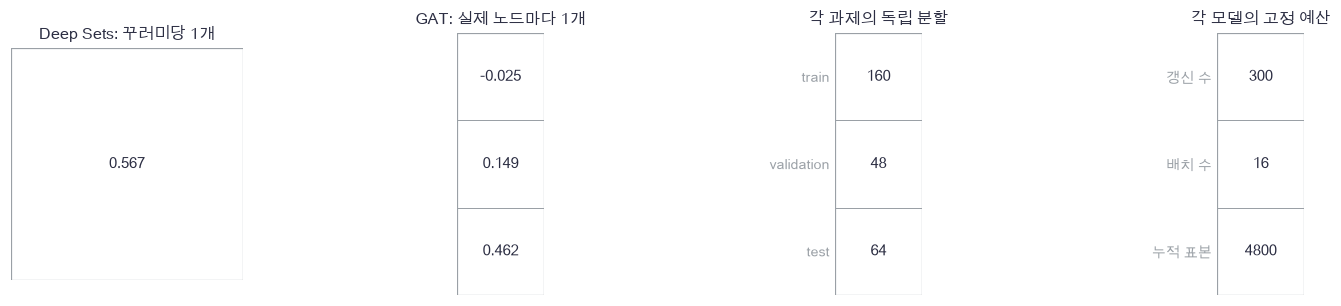

In [40]:
plot_task_plan(plan_set_target,plan_node_target,plan_counts,plan_budget)

🔍 **확인** · 같은 특징을 보아도 꾸러미 정답은 하나이고 노드 정답은 노드 수만큼입니다. 4,800은 고유 학습 관측 수가 아니라 반복을 포함한 누적 처리 수입니다. graph 크기와 이웃 수도 계산 비용에 영향을 주므로 표본 수만으로 두 모델의 연산량이 같다고 말하지 않습니다. 이 구현은 작은 dense $N\times N$ attention 표를 만들며 큰 희소 graph를 위한 효율 구현이 아닙니다.

In [41]:
def regression_loss(prediction, target):
    """꾸러미 한 개당 0.5*(예측-정답)^2의 평균. 두 입력:(B,1) → loss, 같은 shape gradient."""
    residual = prediction-target
    return .5*np.mean(residual**2), residual/residual.size

In [42]:
def node_loss(prediction, target, valid):
    """노드 비용을 graph 안에서 평균한 뒤 graph를 평균합니다. 입력:(B,N,1), mask:(B,N)."""
    counts = np.maximum(valid.sum(axis=1),1)
    weights = valid/counts[:,None]/len(valid)
    residual = prediction-target
    return .5*np.sum(residual**2*weights[...,None]), residual*weights[...,None]

In [43]:
loss_demo_pred = np.array([[[2.],[4.],[99.]],[[1.],[99.],[99.]]])
loss_demo_target = np.zeros_like(loss_demo_pred)
loss_demo_valid = np.array([[1,1,0],[1,0,0]],bool)
loss_demo_value,loss_demo_gradient = node_loss(loss_demo_pred,loss_demo_target,loss_demo_valid)
np.testing.assert_allclose(loss_demo_value,2.75)  # 검산: .5*((4+16)/2+1)/2
np.testing.assert_allclose(loss_demo_gradient,[[[.5],[1.],[0.]],[[.5],[0.],[0.]]])  # 검산: graph 안 평균→graph 평균
np.testing.assert_allclose(node_loss(loss_demo_pred,loss_demo_target,np.zeros_like(loss_demo_valid))[0],0.)  # 검산: 모두 가짜 graph의 손실0
print('노드 손실의 분모와 padding 손계산 통과')

노드 손실의 분모와 padding 손계산 통과


In [44]:
def make_sets(count, seed, minimum=3, maximum=6):
    """붉기·무게의 중복 허용 꾸러미. → X:(B,maximum,2), valid:(B,maximum), target:(B,1)."""
    rng = np.random.default_rng(seed)
    sizes = rng.integers(minimum,maximum+1,size=count)
    valid = np.arange(maximum)[None,:] < sizes[:,None]
    X = rng.uniform(-1,1,(count,maximum,2))*valid[...,None]
    fruit_score = X[...,0]**2 + .3*X[...,1]
    target = np.sum(fruit_score*valid,axis=1,keepdims=True)/sizes[:,None]
    return X, valid, target

In [45]:
def make_graphs(count, seed, minimum=3, maximum=6, edge_probability=.35):
    """특징과 독립인 방향 edge를 만듭니다. → X, valid, A, node target. target은 이웃 평균 특징의 tanh."""
    # 쓰는 것: edge_mask (3절)
    rng = np.random.default_rng(seed)
    sizes = rng.integers(minimum,maximum+1,size=count)
    valid = np.arange(maximum)[None,:] < sizes[:,None]
    X = rng.uniform(-1,1,(count,maximum,2))*valid[...,None]
    adjacency = rng.random((count,maximum,maximum)) < edge_probability
    mask = edge_mask(adjacency,valid)
    denominator = np.maximum(mask.sum(axis=-1,keepdims=True),1)
    mean_features = (mask.astype(float) @ X)/denominator
    target = np.tanh(.7*mean_features[...,0]-.4*mean_features[...,1])[...,None]*valid[...,None]
    return X, valid, adjacency, target

In [46]:
def adam_step(parameters, gradients, state, step, learning_rate=.02):
    """각 배열의 Adam 상태를 갱신합니다. step은1부터, parameters와 state를 제자리 갱신합니다."""
    for key,value in parameters.items():
        first,second = state[key]
        first = .9*first+.1*gradients[key]
        second = .999*second+.001*gradients[key]**2
        value -= learning_rate*(first/(1-.9**step))/(np.sqrt(second/(1-.999**step))+1e-8)
        state[key] = first,second

In [47]:
def train_sets(initial, train, validation, schedule):
    """정해진 배치 표만 사용해 Deep Sets를 학습합니다. → 최종 parameters, validation MSE 기록."""
    # 쓰는 것: regression_loss (5절) · sets_backward (2절) · sets_forward (2절)
    parameters = {key:value.copy() for key,value in initial.items()}
    state = {key:(np.zeros_like(value),np.zeros_like(value)) for key,value in parameters.items()}
    X,valid,target = train
    VX,VM,VY = validation
    history = []
    for step in range(len(schedule)+1):
        if step%50==0:
            history.append(2*regression_loss(sets_forward(VX,VM,parameters)[0],VY)[0])
        if step==len(schedule):
            break
        index = schedule[step]
        prediction,cache = sets_forward(X[index],valid[index],parameters)
        loss,G = regression_loss(prediction,target[index])
        dX,gradients = sets_backward(G,cache)
        adam_step(parameters,gradients,state,step+1)
    return parameters,history

In [48]:
def train_gat(initial, train, validation, schedule):
    """정해진 배치 표만 사용해 GAT를 학습합니다. → 최종 parameters, graph별 동일 비중 validation MSE."""
    # 쓰는 것: gat_backward (4절) · gat_forward (4절) · node_loss (5절)
    parameters = {key:value.copy() for key,value in initial.items()}
    state = {key:(np.zeros_like(value),np.zeros_like(value)) for key,value in parameters.items()}
    X,valid,adjacency,target = train
    VX,VM,VA,VY = validation
    history = []
    for step in range(len(schedule)+1):
        if step%50==0:
            history.append(2*node_loss(gat_forward(VX,VM,VA,parameters)[0],VY,VM)[0])
        if step==len(schedule):
            break
        index = schedule[step]
        prediction,cache = gat_forward(X[index],valid[index],adjacency[index],parameters)
        loss,G = node_loss(prediction,target[index],valid[index])
        dX,gradients,draw = gat_backward(G,cache)
        adam_step(parameters,gradients,state,step+1)
    return parameters,history

In [49]:
# 쓰는 것: BATCH (5절) · STEPS (5절) · TEST_COUNT (5절) · TRAIN_COUNT (5절) · VALID_COUNT (5절) · init_gat (4절) · init_sets (2절) · make_graphs (5절) · make_sets (5절)
set_train,set_validation,set_test = make_sets(TRAIN_COUNT,230),make_sets(VALID_COUNT,231),make_sets(TEST_COUNT,232)
graph_train,graph_validation,graph_test = make_graphs(TRAIN_COUNT,240),make_graphs(VALID_COUNT,241),make_graphs(TEST_COUNT,242)
set_initial,graph_initial = init_sets(210),init_gat(211)
training_schedule = np.random.default_rng(250).integers(0,TRAIN_COUNT,size=(STEPS,BATCH))
training_start = time.perf_counter()
set_trained,set_history = train_sets(set_initial,set_train,set_validation,training_schedule)
graph_trained,graph_history = train_gat(graph_initial,graph_train,graph_validation,training_schedule)
training_seconds = time.perf_counter()-training_start
history_steps = np.arange(0,STEPS+1,50)
print('parameter 수: Deep Sets',sum(value.size for value in set_trained.values()),'GAT',sum(value.size for value in graph_trained.values()))
print('두 학습 시간:',round(training_seconds,3),'초')
assert np.all(np.isfinite(set_history)), '집합 validation 손실이 유한해야 합니다'
assert np.all(np.isfinite(graph_history)), 'graph validation 손실이 유한해야 합니다'

parameter 수: Deep Sets 85 GAT 41
두 학습 시간: 0.056 초


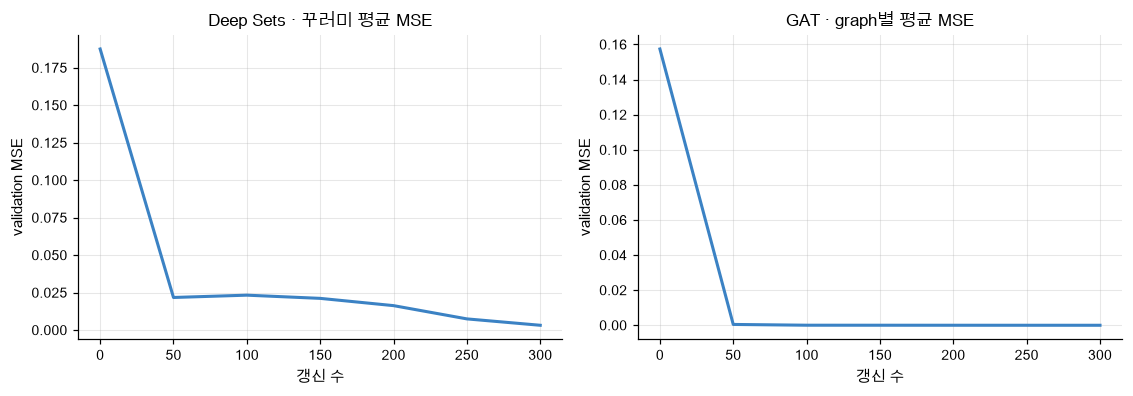

In [50]:
plot_learning_curves(history_steps,set_history,graph_history)

🔍 **확인** · 곡선은 실제 validation 결과이며 서로 다른 과제의 두 패널입니다. 작은 합성 예제의 오차 감소는 이 구현의 학습 경로가 작동한다는 증거입니다. 실험 seed 하나의 결과를 보편적 성능 순위로 해석하지 않습니다. test는 아래에서 각 최종 모델로 한 번 예측하고 그림에도 같은 값을 씁니다.

In [51]:
# 쓰는 것: gat_forward (4절) · node_loss (5절) · regression_loss (5절) · sets_forward (2절)
set_test_X,set_test_valid,set_test_target = set_test
graph_test_X,graph_test_valid,graph_test_A,graph_test_target = graph_test
set_test_prediction = sets_forward(set_test_X,set_test_valid,set_trained)[0]
graph_test_prediction = gat_forward(graph_test_X,graph_test_valid,graph_test_A,graph_trained)[0]
set_test_mse = 2*regression_loss(set_test_prediction,set_test_target)[0]
graph_test_mse = 2*node_loss(graph_test_prediction,graph_test_target,graph_test_valid)[0]
set_train_mean = set_train[2].mean()
graph_train_mean = np.mean(np.sum(graph_train[3][...,0]*graph_train[1],axis=1)/graph_train[1].sum(axis=1))
set_constant_mse = 2*regression_loss(np.full_like(set_test_target,set_train_mean),set_test_target)[0]
graph_constant_mse = 2*node_loss(np.full_like(graph_test_target,graph_train_mean),graph_test_target,graph_test_valid)[0]
print('꾸러미 test MSE / train평균 상수 기준선:',set_test_mse,set_constant_mse)
print('graph별 test MSE / train평균 상수 기준선:',graph_test_mse,graph_constant_mse)
plot_node_target = graph_test_target[...,0][graph_test_valid]
plot_node_prediction = graph_test_prediction[...,0][graph_test_valid]
plot_reference = np.array([-1.,1.])

꾸러미 test MSE / train평균 상수 기준선: 0.004111271911862575 0.02231841422643538
graph별 test MSE / train평균 상수 기준선: 7.244632604341778e-06 0.10769431823118104


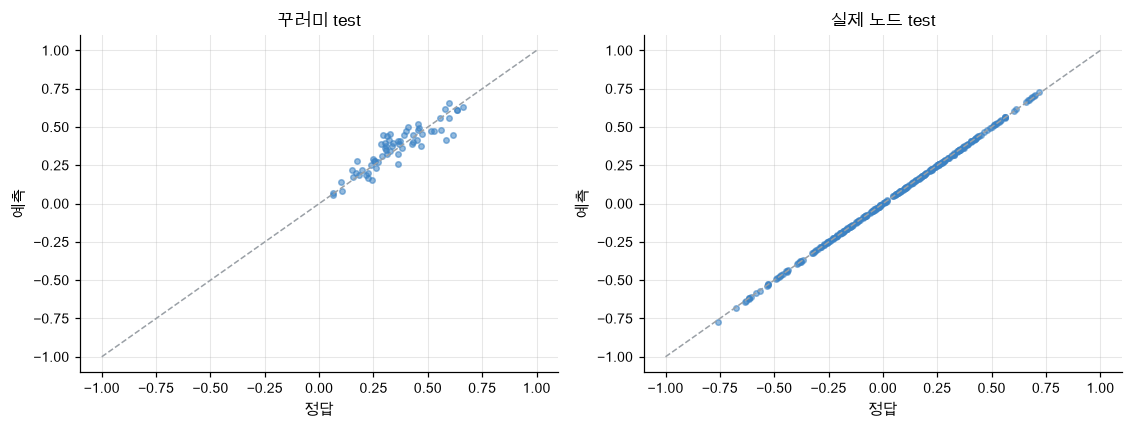

In [52]:
plot_heldout_predictions(set_test_target.ravel(),set_test_prediction.ravel(),plot_node_target,plot_node_prediction,plot_reference)

🔍 **확인** · 점을 성능이 좋은 관측만 골라 그리지 않고 test 전체에서 가져왔습니다. 오른쪽 그림은 실제 노드마다 점 하나라 큰 graph가 더 많은 점을 내지만, 보고한 MSE는 **graph마다 같은 비중**입니다. 비교용 상수는 train 정답만으로 정했습니다.

이제 같은 test 관측의 순서를 바꿉니다. graph의 입력·mask·adjacency 두 축·노드 정답을 모두 함께 움직여 loss와 backward까지 대조합니다. padding 자리를 추가해 큰 가짜 값을 넣어도 실제 출력·기울기에 영향이 없어야 합니다.

In [53]:
def check_trained_symmetries(set_parameters,graph_parameters,set_data,graph_data):
    """고정 test에서 순열·loss·gradient·padding 성질을 검사합니다. 모델 갱신은 하지 않습니다."""
    # 쓰는 것: gat_backward (4절) · gat_forward (4절) · node_loss (5절) · sets_forward (2절)
    # 1. 집합 출력은 순열·전체 복제·padding 추가에 불변입니다.
    X,V,Y = set_data
    order = np.random.default_rng(251).permutation(X.shape[1])
    base = sets_forward(X,V,set_parameters)[0]
    changed = sets_forward(X[:,order],V[:,order],set_parameters)[0]
    np.testing.assert_allclose(changed,base,atol=1e-12)  # 검산: heldout 집합 순열
    doubled = sets_forward(np.repeat(X,2,axis=1),np.repeat(V,2,axis=1),set_parameters)[0]
    np.testing.assert_allclose(doubled,base,atol=1e-12)  # 검산: mean 모델의 전체 중복
    padded_X = np.concatenate([X,np.full((len(X),2,2),100.)],axis=1)
    padded_V = np.concatenate([V,np.zeros((len(X),2),bool)],axis=1)
    np.testing.assert_allclose(sets_forward(padded_X,padded_V,set_parameters)[0],base,atol=1e-12)  # 검산: 가짜 원소 추가 무관
    # 2. graph는 특징·mask·adjacency 양축·정답을 동시에 옮깁니다.
    X,V,A,Y = graph_data
    order = np.random.default_rng(252).permutation(X.shape[1])
    output,cache = gat_forward(X,V,A,graph_parameters)
    permuted,pcache = gat_forward(X[:,order],V[:,order],A[:,order][:,:,order],graph_parameters)
    np.testing.assert_allclose(permuted,output[:,order],atol=1e-12)  # 검산: heldout 노드 등변
    loss,G = node_loss(output,Y,V)
    ploss,pG = node_loss(permuted,Y[:,order],V[:,order])
    np.testing.assert_allclose(ploss,loss,atol=1e-12)  # 검산: 정답도 함께 옮긴 손실 불변
    dX,grads,draw = gat_backward(G,cache)
    pdX,pgrads,pdraw = gat_backward(pG,pcache)
    np.testing.assert_allclose(pdX,dX[:,order],atol=1e-12)  # 검산: 입력 기울기도 등변
    for key in grads:
        np.testing.assert_allclose(pgrads[key],grads[key],atol=1e-12)  # 검산: 공유 parameter 기울기 불변
    np.testing.assert_array_equal(draw[~cache[7]],0.)  # 검산: 학습된 모델의 masked edge 미분0
    return float(np.max(np.abs(changed-base))),float(np.max(np.abs(permuted-output[:,order])))

In [54]:
def check_graph_padding(parameters,data):
    """큰 가짜 노드·가짜 연결을 추가해 실제 출력과 padding 입력 gradient가 변하지 않는지 확인합니다."""
    # 쓰는 것: gat_backward (4절) · gat_forward (4절)
    X,V,A,Y = data
    base = gat_forward(X,V,A,parameters)[0]
    PX = np.concatenate([X,np.full((len(X),2,2),100.)],axis=1)
    PV = np.concatenate([V,np.zeros((len(X),2),bool)],axis=1)
    PA = np.pad(A,((0,0),(0,2),(0,2)),constant_values=True)
    output,cache = gat_forward(PX,PV,PA,parameters)
    np.testing.assert_allclose(output[:,:X.shape[1]],base,atol=1e-12)  # 검산: 가짜 연결·큰 특징도 실제 출력 불변
    np.testing.assert_array_equal(output[:,X.shape[1]:],0.)  # 검산: padding 최종 출력은0
    dX,gradients,draw = gat_backward(np.ones_like(output),cache)
    np.testing.assert_array_equal(dX[~PV],0.)  # 검산: 새 padding을 포함한 입력 미분0
    np.testing.assert_array_equal(draw[~cache[7]],0.)  # 검산: padding과 연결된 모든 점수 미분0
    return float(np.max(np.abs(output[:,:X.shape[1]]-base)))

In [55]:
# 쓰는 것: graph_test (5절) · graph_trained (5절) · set_test (5절) · set_trained (5절)
print('heldout 순열 최대오차(set,graph):',check_trained_symmetries(set_trained,graph_trained,set_test,graph_test))
print('큰 padding 추가 최대오차:',check_graph_padding(graph_trained,graph_test))
set_snapshot = {key:value.copy() for key,value in set_trained.items()}
graph_snapshot = {key:value.copy() for key,value in graph_trained.items()}

heldout 순열 최대오차(set,graph): (2.7755575615628914e-16, 1.1102230246251565e-16)
큰 padding 추가 최대오차: 1.1102230246251565e-16


🔍 **확인** · 순열과 padding은 같은 문제의 표현만 바꾸는 검사이므로 정확히 같은 예측을 기대합니다. 다음의 **크기·이웃 수 변형**은 데이터 분포와 정답을 바꾸는 별도 평가이므로 MSE가 같을 필요는 없습니다. 기본 test와 따로 정한 seed를 사용하고, backward를 계산하더라도 optimizer를 호출하지 않습니다.

In [56]:
def inspect_set_size(parameters,data):
    """새 크기의 집합에서 forward/backward를 검사하고 평균 크기·MSE를 반환합니다. 갱신은 없습니다."""
    # 쓰는 것: regression_loss (5절) · sets_backward (2절) · sets_forward (2절)
    X,V,Y = data
    prediction,cache = sets_forward(X,V,parameters)
    loss,G = regression_loss(prediction,Y)
    dX,gradients = sets_backward(G,cache)
    assert dX.shape == X.shape, '원소 수가 바뀌어도 입력 미분 shape가 같아야 합니다'
    assert all(np.all(np.isfinite(value)) for value in gradients.values()), '변형의 모든 parameter 미분이 유한해야 합니다'
    np.testing.assert_array_equal(dX[~V],0.)  # 검산: 새 크기의 padding gradient0
    return [float(V.sum(axis=1).mean()),float(2*loss)]

In [57]:
def inspect_graph_variant(parameters,data):
    """고정 GAT로 크기·이웃 수 변형의 forward/backward를 검사합니다. → 평균 노드/이웃 수, MSE."""
    # 쓰는 것: gat_backward (4절) · gat_forward (4절) · node_loss (5절)
    X,V,A,Y = data
    prediction,cache = gat_forward(X,V,A,parameters)
    loss,G = node_loss(prediction,Y,V)
    dX,gradients,draw = gat_backward(G,cache)
    assert prediction.shape == Y.shape, '노드 정답과 예측 shape가 같아야 합니다'
    assert dX.shape == X.shape, '노드 수가 바뀌어도 입력 미분 shape가 같아야 합니다'
    assert all(np.all(np.isfinite(value)) for value in gradients.values()), '변형의 모든 parameter 미분이 유한해야 합니다'
    np.testing.assert_array_equal(draw[~cache[7]],0.)  # 검산: 새 이웃 규칙에서도 masked gradient0
    degree = cache[7].sum(axis=-1)
    return [float(V.sum(axis=1).mean()),float(degree[V].mean()),float(2*loss)]

In [58]:
# 쓰는 것: TEST_COUNT (5절) · graph_test (5절) · graph_trained (5절) · make_graphs (5절) · make_sets (5절) · set_test (5절) · set_trained (5절)
set_variants = [set_test,make_sets(TEST_COUNT,233,1,2),make_sets(TEST_COUNT,234,8,10)]
set_variant_names = ['기본 3–6','작은 1–2','큰 8–10']
set_variant_values = np.array([inspect_set_size(set_trained,data) for data in set_variants])
graph_variants = [graph_test,make_graphs(TEST_COUNT,243,3,6,0.),make_graphs(TEST_COUNT,243,3,6,.9),make_graphs(TEST_COUNT,244,8,10,.35)]
graph_variant_names = ['기본 p=.35','self-loop만','조밀 p=.9','큰 8–10']
graph_variant_values = np.array([inspect_graph_variant(graph_trained,data) for data in graph_variants])
for key in set_trained:
    np.testing.assert_array_equal(set_trained[key],set_snapshot[key])  # 검산: 집합 변형 진단은 모델 불변
for key in graph_trained:
    np.testing.assert_array_equal(graph_trained[key],graph_snapshot[key])  # 검산: graph 변형 진단은 모델 불변
print('모든 크기·이웃 변형의 forward/backward 및 parameters 불변 통과')

모든 크기·이웃 변형의 forward/backward 및 parameters 불변 통과


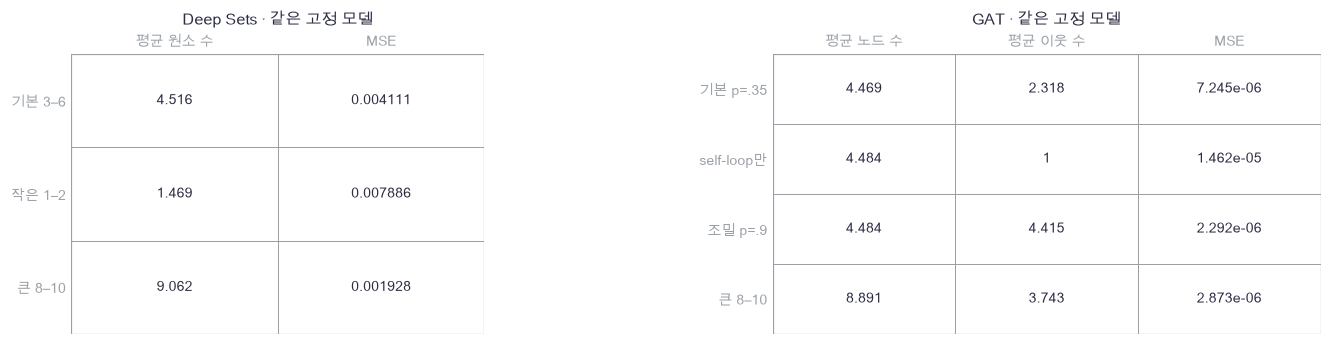

In [59]:
plot_size_degree_metrics(set_variant_values,graph_variant_values,set_variant_names,graph_variant_names)

🔍 **확인** · 이웃 수는 self-loop를 포함해 **실제 노드 전체에서 평균한 값**입니다. MSE는 graph마다 노드를 먼저 평균하므로 두 통계의 분모가 다릅니다. 희소·조밀 두 변형은 같은 seed와 같은 특징을 쓰고 edge 확률만 다릅니다. 크기 변형은 별도 seed의 새로운 관측입니다. 이 결과를 보고 설정을 바꾼다면 지금의 test를 그대로 독립 최종 성능으로 재사용하지 않습니다.

### ✏️ 연습 5 · graph마다 같은 비중으로 오차 평균하기

`squared_error:(B,N)`는 이미 제곱한 노드 오차입니다. 각 graph의 실제 노드를 먼저 평균하고 graph 축을 평균하세요. 1/2은 붙이지 않는 MSE입니다.

In [60]:
def exercise_graph_balanced_mse(squared_error,valid):
    """연습 5: graph 안 평균 뒤 graph 평균. (B,N) 두 배열 → scalar."""
    count = np.maximum(valid.sum(axis=1),1)
    ### 구현할 내용: 실제 오차 합/count를 graph 축 평균
    raise NotImplementedError
    return mse

In [61]:
def check_graph_balanced_mse(candidate):
    """두 노드 graph와 한 노드 graph의 비중을 손계산합니다."""
    error = np.array([[1.,9.,99.],[4.,99.,99.]])
    valid = np.array([[1,1,0],[1,0,0]],bool)
    np.testing.assert_allclose(candidate(error,valid),4.5)  # 검산: ((1+9)/2+4)/2
    print('graph별 MSE: 손계산과 일치합니다.')

run_check(check_graph_balanced_mse,exercise_graph_balanced_mse,hint='mse = np.mean(np.sum(squared_error*valid,axis=1)/count)')

☐ exercise_graph_balanced_mse: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: mse = np.mean(np.sum(squared_error*valid,axis=1)/count)


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
mse = np.mean(np.sum(squared_error*valid,axis=1)/count)
```

</details>

## ✏️ 마무리 연습 A–D

순열·빈 입력·빈 이웃·서로 다른 노드 수를 각각 한두 줄로 다시 확인합니다. 앞의 절 연습을 푼 뒤 정답을 접고 진행하세요.

### ✏️ 연습 A · 그래프의 이름표를 함께 옮기기

배치 없는 `X:(N,D)`, `A:(N,N)`를 `order` 순서로 바꿉니다. 행 i는 받는 노드, 열 j는 보내는 노드이므로 인접 행렬 두 축을 함께 옮기세요.

In [62]:
def exercise_permute_graph(X,A,order):
    """연습 A: 특징과 adjacency의 동시 순열. → new_X:(N,D), new_A:(N,N)."""
    ### 구현할 내용: X의 행, A의 행과 열을 모두 order로 재배열
    raise NotImplementedError
    return new_X,new_A

In [63]:
def check_permute_graph(candidate):
    """방향 관계의 이름표가 함께 바뀌는지 손계산합니다."""
    X = np.array([[10.],[20.],[30.]])
    A = np.array([[0,1,0],[0,0,1],[0,0,0]])
    new_X,new_A = candidate(X,A,np.array([2,0,1]))
    np.testing.assert_array_equal(new_X,[[30.],[10.],[20.]])  # 검산: 새 이름표의 특징
    np.testing.assert_array_equal(new_A,[[0,0,0],[0,0,1],[1,0,0]])  # 검산: 기존0←1은새1←2
    print('그래프 동시 순열: 손계산과 일치합니다.')

run_check(check_permute_graph,exercise_permute_graph,hint='new_X = X[order]; new_A = A[order][:,order]')

☐ exercise_permute_graph: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: new_X = X[order]; new_A = A[order][:,order]


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
new_X = X[order]
new_A = A[order][:,order]
```

</details>

### ✏️ 연습 B · 빈 꾸러미의 출력은 왜 꼭 0이 아닐까요

빈 꾸러미의 pool은 `g=0`입니다. readout이 `tanh(g@Wr+br)@Wo+bo`일 때 빈 입력의 최종 출력을 한 줄로 계산하세요.

In [64]:
def exercise_empty_readout(br,Wo,bo):
    """연습 B: g=0인 readout의 최종 응답. br:(R,), Wo:(R,1), bo:(1,) → (1,)."""
    ### 구현할 내용: pool이 0이어도 남는 두 편향의 응답
    raise NotImplementedError
    return prediction

In [65]:
def check_empty_readout(candidate):
    """tanh(0)=0과 tanh(arctanh(.5))=.5로 손계산합니다."""
    np.testing.assert_allclose(candidate(np.zeros(2),np.ones((2,1)),np.array([.4])),[.4])  # 검산: 출력 편향만 남음
    br = np.array([np.arctanh(.5),0.])
    np.testing.assert_allclose(candidate(br,np.array([[2.],[7.]]),np.array([.3])),[1.3])  # 검산: .5*2+.3
    print('빈 꾸러미 readout: 손계산과 일치합니다.')

run_check(check_empty_readout,exercise_empty_readout,hint='prediction = np.tanh(br) @ Wo + bo')

☐ exercise_empty_readout: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: prediction = np.tanh(br) @ Wo + bo


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
prediction = np.tanh(br) @ Wo + bo
```

</details>

### ✏️ 연습 C · 이웃이 없는 행의 0 나눗셈 피하기

`exponential:(B,N,N)`은 허용된 이웃에서만 계산한 비음수 지수값이며 나머지는 0입니다. 행 합이 양수인 행만 나누고 빈 행은 0으로 남기세요.

In [66]:
def exercise_safe_normalize(exponential):
    """연습 C: all-masked 행까지 안전한 이웃 정규화. → 입력과 같은 shape."""
    denominator = exponential.sum(axis=-1,keepdims=True)
    ### 구현할 내용: np.divide의 out과 where로 빈 행을 0으로 남기기
    raise NotImplementedError
    return weights

In [67]:
def check_safe_normalize(candidate):
    """0/0행, 두 이웃, 자기 자신 한 이웃을 손계산합니다."""
    values = np.array([[[0.,0.,0.],[2.,6.,0.],[0.,0.,5.]]])
    expected = np.array([[[0.,0.,0.],[.25,.75,0.],[0.,0.,1.]]])
    np.testing.assert_allclose(candidate(values),expected)  # 검산: 빈 행0·양수 행 합1
    print('안전한 이웃 정규화: 손계산과 일치합니다.')

run_check(check_safe_normalize,exercise_safe_normalize,hint='weights = np.divide(exponential,denominator,out=np.zeros_like(exponential),where=denominator>0)')

☐ exercise_safe_normalize: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: weights = np.divide(exponential,denominator,out=np.zeros_like(exponential),where=denominator>0)


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
weights = np.divide(exponential,denominator,out=np.zeros_like(exponential),where=denominator>0)
```

</details>

### ✏️ 연습 D · graph 크기가 달라졌을 때 손실 미분의 분모

`residual:(B,N,1)`와 실제 노드 mask가 주어집니다. `0.5 × graph별 평균 제곱오차`를 graph 축으로 평균한 손실의 예측 미분을 쓰세요.

In [68]:
def exercise_node_loss_gradient(residual,valid):
    """연습 D: 잔차*valid/(B*n_b). residual:(B,N,1), valid:(B,N) → 같은 shape gradient."""
    count = np.maximum(valid.sum(axis=1),1)
    ### 구현할 내용: 노드와 graph 평균 분모를 모두 적용
    raise NotImplementedError
    return gradient

In [69]:
def check_node_loss_gradient(candidate):
    """배치2, 실제 노드 수1과3의 서로 다른 분모를 확인합니다."""
    residual = np.full((2,3,1),6.)
    valid = np.array([[1,0,0],[1,1,1]],bool)
    np.testing.assert_allclose(candidate(residual,valid),[[[3.],[0.],[0.]],[[1.],[1.],[1.]]])  # 검산: 6/(2*1),6/(2*3)
    print('가변 크기 손실 미분: 손계산과 일치합니다.')

run_check(check_node_loss_gradient,exercise_node_loss_gradient,hint='gradient = residual*(valid/count[:,None])[...,None]/len(valid)')

☐ exercise_node_loss_gradient: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: gradient = residual*(valid/count[:,None])[...,None]/len(valid)


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gradient = residual*(valid/count[:,None])[...,None]/len(valid)
```

</details>

### ✏️ 준비도 질문 · 네 가지를 따로 확인합니다

- **설명:** 꾸러미 순서를 바꾸는 것과 adjacency만 바꾸는 것은 어떻게 다른가요? sum·mean·정규화 attention은 중복·개수 정보를 어떻게 다룰까요? → 1–3절
- **수식:** 공유 함수의 등변성과 readout의 불변성, 이웃 softmax의 마지막 축, self-loop·padding·빈 행의 규약, graph별 손실의 $B$와 $n_b$ 분모를 쓸 수 있나요? → 1–5절
- **구현:** Deep Sets의 pool 미분과 GAT의 값·점수 두 경로를 합해 모든 파라미터와 입력까지 backward를 작성할 수 있나요? → 2·4절, 연습 B·C
- **변형 검산:** 노드 특징·mask·adjacency 양축·정답을 동시에 순열하고 loss·입력 미분까지 대조할 수 있나요? 크기·이웃 수를 바꾼 평가에서 학습된 파라미터가 그대로인지 확인할 수 있나요? → 5절, 연습 A·D

### 📎 다음 연결

두 모델의 구조는 순서를 없애거나 이웃을 제한하는 방법이고, 회귀는 이 예제에서 선택한 학습 목적입니다. 분류 손실이나 다른 readout을 붙여도 구조·목적·optimizer·학습 후 예측을 따로 적어 보세요. graph의 대칭을 깨는 위치·식별 정보를 추가한다면 무엇에 대한 순열 성질을 유지할지도 다시 정의해야 합니다.